# Compute abundance change for each allele

This script takes in the single-cell FACS data as input, applies various filtering criteria, and then produces a z-score for the abundance of each allele relative to the reference on the same plate.

In [1]:
import pandas as pd
import numpy as np
from random import choice
import matplotlib.pyplot as plt
import polars as pl
import process_dualipa as proc

In [2]:
dualipa_inputs = "../1_inputs"
dualipa_outputs = "../3_outputs"
meta_outputs = "../../../1_allele_collection/3_outputs"

n_cell_threshold = 800
wt_gfp_threshold = 100

In [3]:
# Read in single-cell measurements
pDEST_DUAL_df = pd.read_parquet(f"{dualipa_outputs}/facs_single_cell.parquet")

# Filter to only keep wells with more than 800 cells
pDEST_DUAL_df = pDEST_DUAL_df[pDEST_DUAL_df['n_cells'] > n_cell_threshold]

In [4]:
# get the mean and median measurements per well
keep_cols = ['symbol', 'node_type', 'nt_change','aa_change', 'pla', 'well', 'coordinates', 'n_cells', 'orf_id', 'mut_id', 'valid_well']
pDEST_DUAL_avg_df = pDEST_DUAL_df[keep_cols + ['avg_gfp', 'avg_mcherry','avg_GFP_mCherry_ratio']].drop_duplicates()
pDEST_DUAL_median_df = pDEST_DUAL_df[keep_cols + ['median_gfp', 'median_mcherry','median_GFP_mCherry_ratio']].drop_duplicates()

## 1. Compute the mean and mediam scores

__Functions for computing is in ```process_dualipa.py```__

Maxime's notes:

    Instead of using Georges' approach to compute the assay's variability, which uses a step with random pairings, 
    Luke suggested to compute a STD from the Log2FC of all individual WT measurements, relative to the mean of the WT of each gene.
    This is a more robust approach, as it does not rely on random pairings.
    This function computes the STD of the Log2FC of all individual WT measurements, relative to the mean of the WT of each gene.
    Returns a tuple with the mean and the STD of the Log2FC of all individual WT measurements, relative to the mean of the WT of each gene.

In [5]:
# _d objects: mean or median GFP_mCherry ratio of each unique (wt orf, plate) combination
# _l objects: list of WT:WT abundances (GFP:mCherry ratios) to estimate assay variability
wt_avg_d, wt_ratio_l = proc.get_wt_variability_d(pDEST_DUAL_avg_df, pDEST_DUAL_df)
wt_median_d, wt_ratio_l_median = proc.get_wt_variability_d_median(pDEST_DUAL_median_df, pDEST_DUAL_df)

In [6]:
wt_std, wt_mean = proc.wt_log2fc_variability(pDEST_DUAL_avg_df, pDEST_DUAL_df)

In [7]:
# Must be two WT replicates on same plate to compute the ratio, otherwise we return a NaN
pDEST_DUAL_avg_allele_df = proc.get_pDEST_DUAL_avg_allele_df(pDEST_DUAL_avg_df, wt_avg_d, wt_ratio_l, wt_std, wt_mean)
pDEST_DUAL_median_allele_df = proc.get_pDEST_DUAL_median_allele_df(pDEST_DUAL_median_df, wt_median_d, wt_ratio_l_median)

In [8]:
mean_df = pl.DataFrame(pDEST_DUAL_avg_allele_df)
median_df = pl.DataFrame(pDEST_DUAL_median_allele_df)

# append metadata and write out files
metadata = pl.read_csv(f"{meta_outputs}/varchamp_seq_confirm_alleles_clinvar_gnomad_dbnsfp_struc_scores_OMIM_MOI_disease_modules.tsv", 
                       separator="\t", infer_schema_length=1000000
).with_columns(
    pl.col("orf_id").cast(pl.Int64).alias("orf_id"),
    pl.col("mut_id").cast(pl.Int64).alias("mut_id")
)

mean_df = mean_df.with_columns(
    pl.col("orf_id").cast(pl.Int64).alias("orf_id"),
    pl.col("mut_id").cast(pl.Int64).alias("mut_id")
).join(metadata, on=["orf_id", "mut_id"], how="left").filter(
    pl.col("valid_well")
)

median_df = median_df.with_columns(
    pl.col("orf_id").cast(pl.Int64).alias("orf_id"),
    pl.col("mut_id").cast(pl.Int64).alias("mut_id")
).join(metadata, on=["orf_id", "mut_id"], how="left").filter(
    pl.col("valid_well")
)

In [11]:
# mean_df
# median_df

## 2. Clean up the duplicate readouts from the same alleles

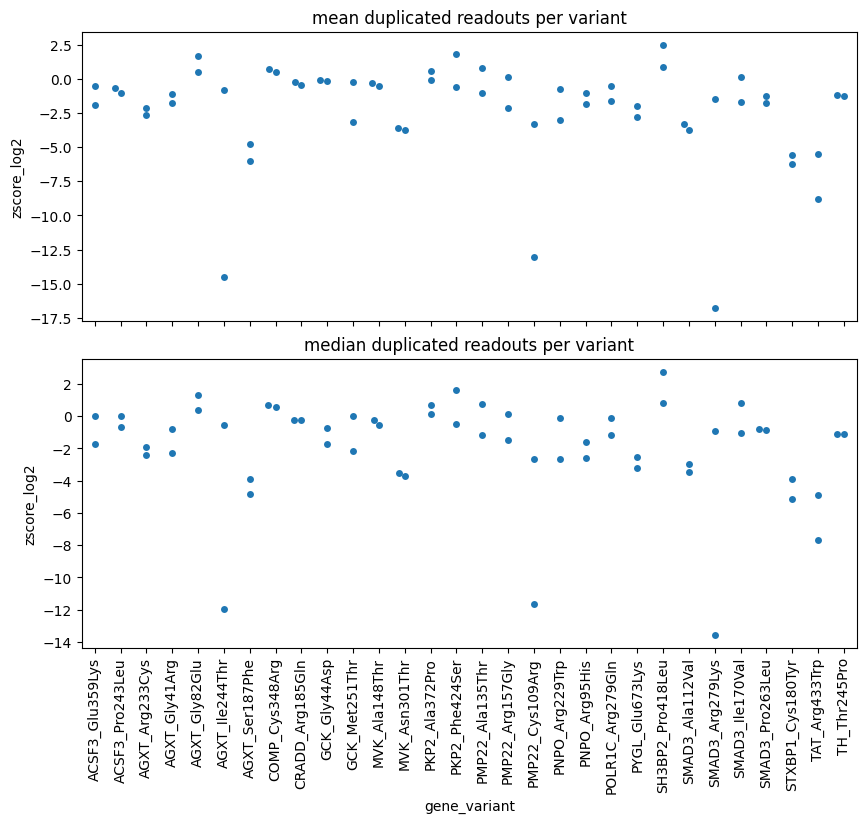

In [12]:
import seaborn as sns

mean_median_dict = {
    "mean": mean_df,
    "median": median_df
}

fig, axes = plt.subplots(2, 1, figsize=(10,8), sharex=True)
for name, df in mean_median_dict.items():
    meta_df = df.filter(
        pl.col("zscore_log2").is_not_null()
    )
    df_dup = meta_df.filter(pl.col("gene_variant").is_duplicated())
    df_no_dup = meta_df.filter(~pl.col("gene_variant").is_duplicated())
    
    ax = axes[0] if name=="mean" else axes[1]
    sns.swarmplot(
        data=df_dup.sort("gene_variant").to_pandas(),
        x="gene_variant",
        y="zscore_log2",
        ax=ax
    )
    ax.set_title(f"{name} duplicated readouts per variant")
    
axes[1].set_xticks(range((df_dup.unique("gene_variant").shape[0])))
axes[1].set_xticklabels(ax.get_xticklabels(), rotation=90)
plt.subplots_adjust(hspace=0.13)
plt.show()

In [13]:
for name, df in mean_median_dict.items():
    meta_df = df.filter(
        pl.col("zscore_log2").is_not_null()
    )
    df_dup = meta_df.filter(pl.col("gene_variant").is_duplicated())
    df_no_dup = meta_df.filter(~pl.col("gene_variant").is_duplicated())
    final_df = pl.concat([
        df_no_dup,
        ## keep the replicate with more n_cells
        df_dup.sort("gene_variant", "n_cells").unique(subset="gene_variant", keep="last"),
    ])
    print(final_df.shape)
    final_df.write_csv(f'{dualipa_outputs}/DUALIPA_{name}_zscore.csv')

(763, 545)
(741, 542)


In [14]:
final_df

symbol,node_type,nt_change,aa_change,pla,well,coordinates,n_cells,orf_id,mut_id,valid_well,median_gfp,median_mcherry,median_GFP_mCherry_ratio,wt_GFP_mCherry_ratio_median,allele_wt_ratio_median,zscore_median,zcat_median,zscore_log2,symbol_right,ensembl_gene_id,ccsb_mutation_id,ccsb_allele_id,spdi,nt_change_right,aa_change_right,collection,entry_plate_orig,entry_well_orig,entry_plate_conso,entry_well_conso,entry_seq_pool,db_plate,db_well,n2h_plate,n2h_well,dualip_plate,…,Assembly_dbnsfp,ChromosomeAccession_dbnsfp,Chromosome_dbnsfp,Start_dbnsfp,Stop_dbnsfp,Cytogenetic_dbnsfp,ReviewStatus_dbnsfp,NumberSubmitters_dbnsfp,Guidelines_dbnsfp,TestedInGTR_dbnsfp,OtherIDs_dbnsfp,SubmitterCategories_dbnsfp,VariationID_dbnsfp,PositionVCF_dbnsfp,ReferenceAlleleVCF_dbnsfp,AlternateAlleleVCF_dbnsfp,SomaticClinicalImpact_dbnsfp,SomaticClinicalImpactLastEvaluated_dbnsfp,ReviewStatusClinicalImpact_dbnsfp,Oncogenicity_dbnsfp,OncogenicityLastEvaluated_dbnsfp,ReviewStatusOncogenicity_dbnsfp,SCVsForAggregateGermlineClassification_dbnsfp,SCVsForAggregateSomaticClinicalImpact_dbnsfp,SCVsForAggregateOncogenicityClassification_dbnsfp,clinvar_nt_change_dbnsfp,clinvar_aa_change_dbnsfp,RefSeq_mRNA_dbnsfp,StarStatus_dbnsfp,clinvar_clnsig_clean_dbnsfp,plddt,rsa,OMIM_IDs,inheritance_pattern,disease_modules,disease_module_count,OMIM_disease_names
str,str,str,str,i64,str,str,i64,i64,i64,bool,f64,f64,f64,f64,f64,f64,i64,f64,str,str,str,str,str,str,str,str,str,str,str,str,f64,str,str,str,str,str,…,str,str,str,f64,f64,str,str,f64,str,str,str,f64,f64,f64,str,str,str,str,str,str,str,str,str,str,str,str,str,str,f64,str,f64,f64,str,str,str,i64,str
"""KCNJ2""","""allele""","""899G>A""","""Gly300Asp""",11,"""D07""","""11_D07""",8822,100016069,2641,true,693.679993,5069.049805,0.133067,0.841771,0.15808,-1.875327,-1,-5.589107,"""KCNJ2""","""ENSG00000123700""","""CCSBVarC008343""","""ALE00008329""","""NC_000017.11:70175938:G:A""","""899G>A""","""Gly300Asp""","""Edgotyping3""","""VUSMutGDEh010""","""G06""","""GDEhDisVCh_40005""","""F10""",1.0,"""VUSMutGDDh010""","""G06""","""VUSN2Hmut_GDN2h_03""","""H09""","""VUSMutpDEST2_16""",…,"""GRCh38""","""NC_000017.11""","""17""",7.0175938e7,7.0175938e7,"""17q24.3""","""criteria provided, multiple su…",4.0,"""-""","""N""","""ClinGen:CA329702""",3.0,67588.0,7.0175938e7,"""G""","""A""","""-""","""-""","""-""","""-""","""-""","""-""","""SCV001446813|SCV004571381""","""-""","""-""","""899G>A ""","""Gly300Asp""","""NM_000891.3""",2.0,"""1_Pathogenic""",94.45,0.059524,"""['170390', '609622', '170390']""","""autosomal dominant""","""Rare genetic cardiac disease; …",2,"""ANDERSEN CARDIODYSRHYTHMIC PER…"
"""HBD""","""allele""","""174C>A""","""Asn58Lys""",26,"""E05""","""26_E05""",9609,13796,218146,true,33.84,2474.280029,0.012192,0.077713,0.156882,-1.877915,-1,-5.612572,"""HBD""","""ENSG00000223609""","""CCSBVarC006560""","""ALE00006559""","""NC_000011.10:5234132:G:T""","""174C>A""","""Asn58Lys""","""CEGS2""","""CegsMutGDEh1047""","""D02""","""GDEhDisVCh_40036""","""D03""",2.0,"""CegsMutGDDh1047""","""D02""","""VUSN2Hmut_GDN2h_10""","""C04""","""VUSMutpDEST2_11""",…,"""GRCh38""","""NC_000011.10""","""11""",5.234132e6,5.234132e6,"""11p15.4""","""no assertion criteria provided""",1.0,"""-""","""N""","""HBVAR:1167,ClinGen:CA124701,Un…",1.0,15081.0,5.234132e6,"""G""","""T""","""-""","""-""","""-""","""-""","""-""","""-""","""SCV000036502""","""-""","""-""","""174C>A ""","""Asn58Lys""","""NM_000519.4""",null,"""5_Others""",98.57,0.076433,null,null,"""Rare genetic hematologic disea…",1,null
"""SMAD3""","""allele""","""376C>T""","""His126Tyr""",20,"""H03""","""20_H03""",9096,11805,2128,true,993.600037,3757.339966,0.267095,1.033889,0.25834,-1.658717,-1,-4.073922,"""SMAD3""","""ENSG00000166949""","""CCSBVarC007714""","""ALE00007700""","""NC_000015.10:67165064:C:T""","""376C>T""","""His126Tyr""","""Edgotyping3""","""VUSMutGDEh004""","""D11""","""GDEhDisVCh_40014""","""D06""",2.0,"""VUSMutGDDh004""","""D11""",null,null,"""VUSMutpDEST2_09""",…,"""GRCh38""",